# Live evaluation of the unified model

Runs the unified CRNN checkpoint against **freshly downloaded** captchas from each source in `captix.download.available_sources()`. The live images are never seen during training, so this is the real generalization test — any source with a label accuracy that drops here vs. `eval_per_dataset.ipynb` was overfitting to the training corpus.

We have no ground-truth labels for these live captchas, so this notebook only shows images with the model's predictions — no accuracy numbers. Sources that are down or have no downloaded files are skipped with a warning.

## Step 1 — Download fresh captchas

Run the command below in a shell (or keep the code cell as-is — it invokes the same CLI entry point from Python). It creates one subdirectory per source under `data_live/`.

```bash
download_captchas --source all --n 16 --dest notebooks/data_live
```

Some sources may be temporarily unreachable or have changed their markup — those will be skipped with a warning and the notebook simply shows fewer rows for them.

In [16]:
from pathlib import Path

from captix import available_sources, download_captchas

DATA_LIVE = Path("data_live")
N_PER_SOURCE = 16

for src in available_sources():
    target = DATA_LIVE / src
    existing = list(target.glob("*")) if target.exists() else []
    if len(existing) >= N_PER_SOURCE:
        print(f"[{src}] already has {len(existing)} files — skipping download")
        continue
    print(f"[{src}] fetching up to {N_PER_SOURCE}")
    saved = download_captchas(src, N_PER_SOURCE, target, timeout=20.0)
    print(f"[{src}] saved {len(saved)}")

[cadesp] already has 16 files — skipping download
[esaj] fetching up to 16


C:\Users\jtrec\Documents\jtrecenti\txtcaptcha\src\txtcaptcha\download\_base.py:145: UserWarning: [esaj] fetch failed (DownloadError): esaj: non-JSON response
  warnings.warn(f"[{source}] fetch failed ({type(e).__name__}): {e}")


[esaj] saved 0
[jucesp] already has 16 files — skipping download
[rfb] fetching up to 16


C:\Users\jtrec\Documents\jtrecenti\txtcaptcha\src\txtcaptcha\download\_base.py:145: UserWarning: [rfb] fetch failed (DownloadError): rfb session: HTTP 404
  warnings.warn(f"[{source}] fetch failed ({type(e).__name__}): {e}")
C:\Users\jtrec\Documents\jtrecenti\txtcaptcha\src\txtcaptcha\download\_base.py:145: UserWarning: [rfb] fetch failed (ConnectionError): ('Connection aborted.', RemoteDisconnected('Remote end closed connection without response'))
  warnings.warn(f"[{source}] fetch failed ({type(e).__name__}): {e}")


[rfb] saved 0
[sei] fetching up to 16


...

[sei] saved 0
[tjmg] already has 16 files — skipping download
[tjpe] already has 16 files — skipping download
[tjrs] fetching up to 16


C:\Users\jtrec\Documents\jtrecenti\txtcaptcha\src\txtcaptcha\download\_base.py:145: UserWarning: [tjrs] fetch failed (DownloadError): tjrs captcha: HTTP 404
  warnings.warn(f"[{source}] fetch failed ({type(e).__name__}): {e}")


[tjrs] saved 0
[trf5] already has 16 files — skipping download
[trt] fetching up to 16


C:\Users\jtrec\Documents\jtrecenti\txtcaptcha\src\txtcaptcha\download\_base.py:145: UserWarning: [trt] fetch failed (DownloadError): trt captcha: HTTP 405
  warnings.warn(f"[{source}] fetch failed ({type(e).__name__}): {e}")


[trt] saved 0


## Step 2 — Load the model

In [17]:
from captix import decrypt, load_model, read_captcha

MODEL_PATH = Path("txtcaptcha_unified.pt")
model = load_model(MODEL_PATH)
model.eval()
print(f"Loaded model with vocab size {len(model.vocab)}")

Loaded model with vocab size 62


## Step 3 — Predict and display per source

In [18]:
captcha_length = {
    "cadesp": 4,
    "jucesp": 5,
    "tjmg": 5,
    "tjpe": 5,
    "trf5": 6,
    "esaj": 4,
    "rfb": 5,
    "sei": 4,
    "tjrs": 4,
    "trt": 5,
}

[esaj] no live captchas found — skipping
[rfb] no live captchas found — skipping
[sei] no live captchas found — skipping
[tjrs] no live captchas found — skipping
[trt] no live captchas found — skipping


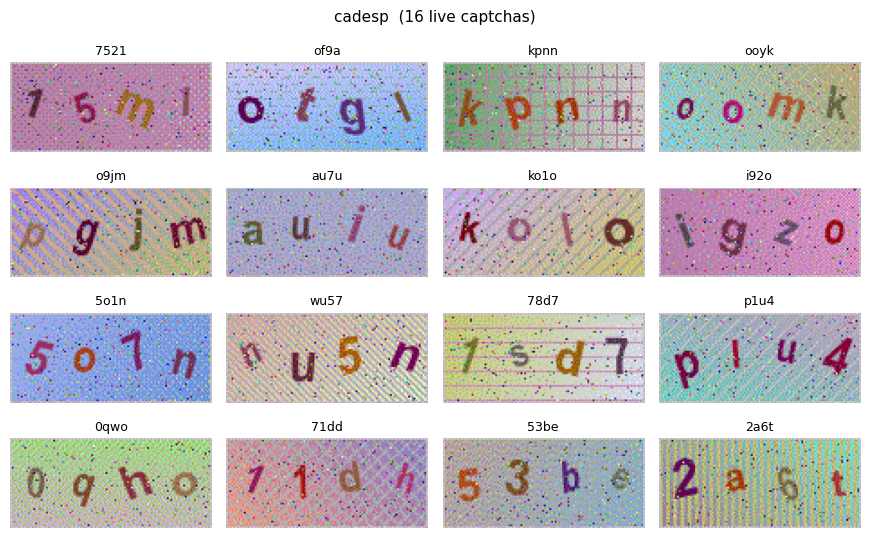

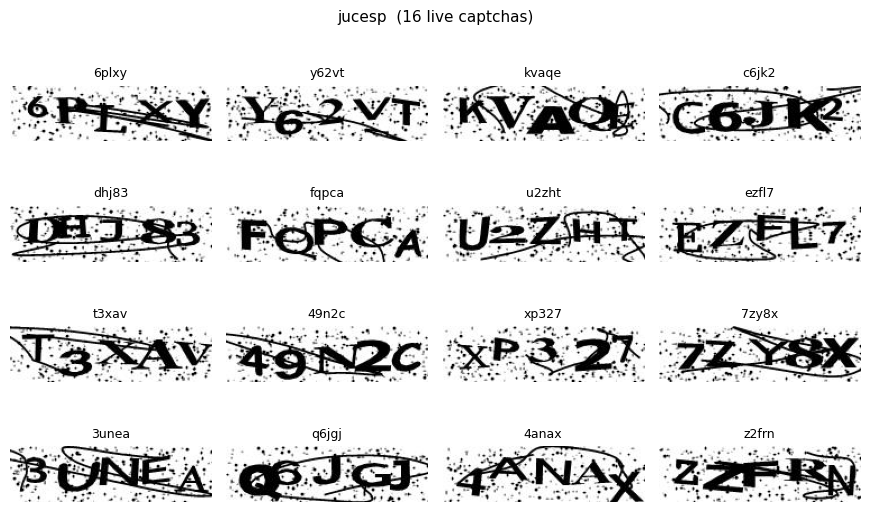

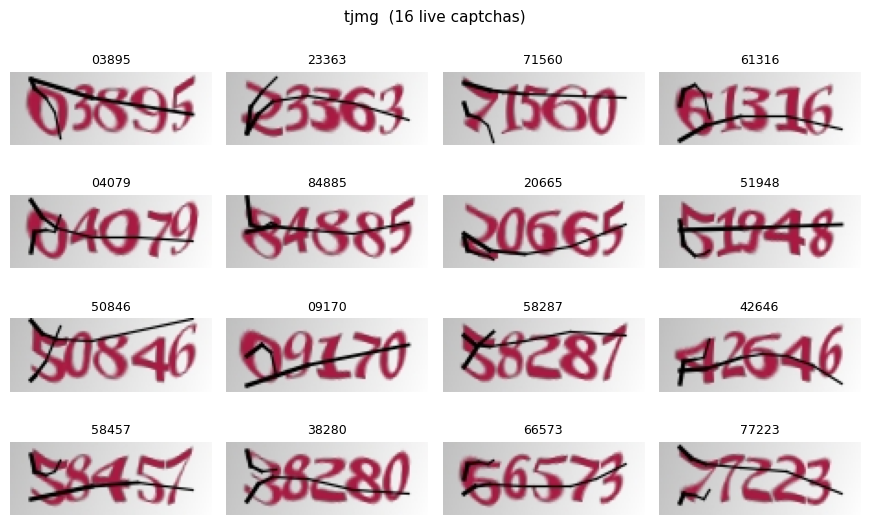

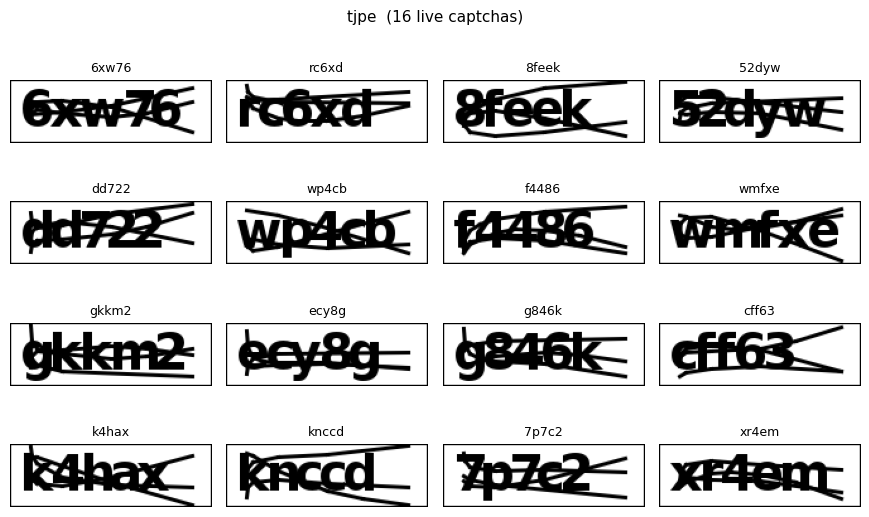

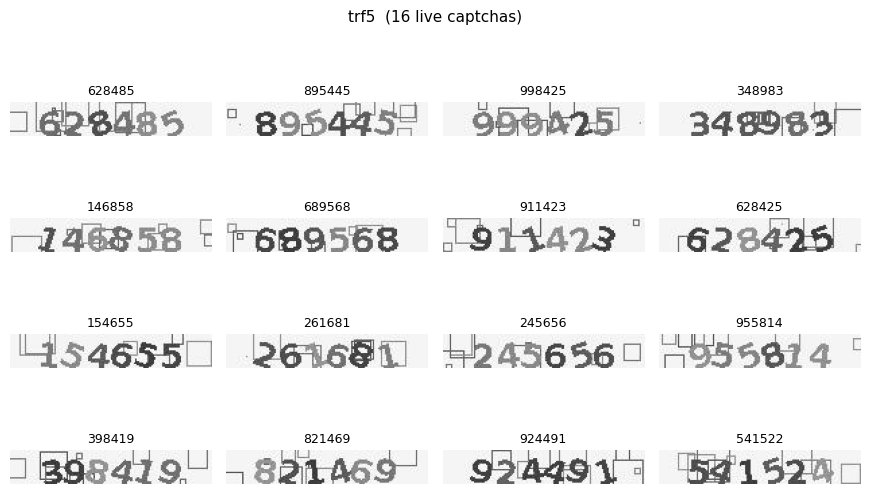

In [19]:
import matplotlib.pyplot as plt

_IMG_EXTS = {".png", ".jpg", ".jpeg", ".bmp", ".gif", ".tiff", ".webp"}


def list_live_files(src: str) -> list[Path]:
    root = DATA_LIVE / src
    if not root.exists():
        return []
    return sorted(p for p in root.iterdir() if p.suffix.lower() in _IMG_EXTS)


def show_live(src: str, cols: int = 4):
    files = list_live_files(src)
    if not files:
        print(f"[{src}] no live captchas found — skipping")
        return None
    cap = read_captcha(files)
    preds = decrypt(cap, model, case_sensitive=False, length=captcha_length[src])
    rows = (len(cap) + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 2.2, rows * 1.4))
    axes = axes.flatten() if hasattr(axes, "flatten") else [axes]
    for ax, img, pred in zip(axes, cap.images, preds):
        ax.imshow(img)
        ax.axis("off")
        ax.set_title(pred, fontsize=9)
    for ax in axes[len(cap) :]:
        ax.axis("off")
    fig.suptitle(f"{src}  ({len(cap)} live captchas)", fontsize=11)
    fig.tight_layout()
    return fig


for src in available_sources():
    show_live(src)
plt.show()